In [20]:
import laspy
import os
import numpy as np
import open3d as o3d
import geopandas as gpd
import matplotlib.pyplot as plt


<h2>Load a single -laz-file</h2>

In [16]:
path = "data/sample_roofdata_50"
las = laspy.read(path + "/10444144.laz")

<h2>Metadata of a single .laz-file</h2>

In [17]:
print("Antall punkter:", las.header.point_count)
print("Skala:", las.header.scales)
print("Offset:", las.header.offsets)
print("Koordinatgrenser:", las.header.mins, las.header.maxs)
print("CRS:", las.header.parse_crs())

Antall punkter: 1403
Skala: [0.01 0.01 0.01]
Offset: [0. 0. 0.]
Koordinatgrenser: [5.70972050e+05 7.03067314e+06 9.77400000e+01] [5.70982180e+05 7.03068727e+06 9.99200000e+01]
CRS: None


<h1>Attributes of a single .laz-point</h1>

In [18]:
attributes =[dimension.name for dimension in las.point_format.dimensions]
for att in attributes:
    print(att)

X
Y
Z
intensity
return_number
number_of_returns
scan_direction_flag
edge_of_flight_line
classification
synthetic
key_point
withheld
scan_angle_rank
user_data
point_source_id
gps_time
red
green
blue


<h2>Above view of a single .laz-point<h2>

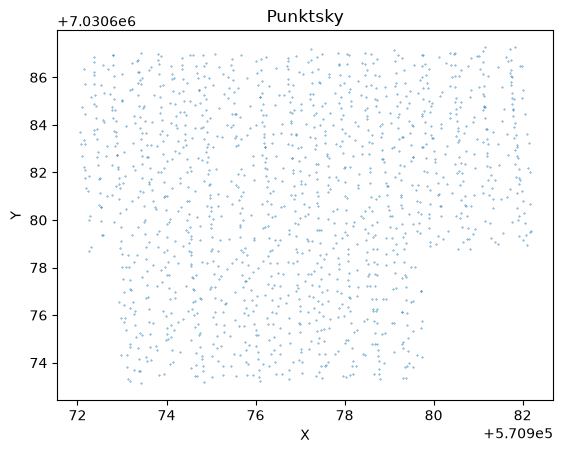

In [22]:
xy = np.vstack((las.x, las.y)).T
plt.scatter(xy[:, 0], xy[:, 1], s=0.1)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Punktsky")
plt.show()

<h2>3D visualization of a single .laz-fil<h2>

In [ ]:
path = "data/sample_roofdata_50"

las = laspy.read(path + "/10444144.laz")

xyz = np.vstack((las.x, las.y, las.z))


pcd_o3d = o3d.geometry.PointCloud()
pcd_o3d.points = o3d.utility.Vector3dVector(xyz.T)

pcd_center = pcd_o3d.get_center()

pcd_o3d.translate(-pcd_center)

o3d.visualization.draw_geometries([pcd_o3d])

In [25]:
path = "data/sample_roofdata_50"

files = os.listdir(path)

print(files)

print([dimension.name for dimension in las[0].point_format.dimensions])

xyz = np.vstack((
    np.hstack([i.x for i in las]),
    np.hstack([i.y for i in las]),
    np.hstack([i.z for i in las])
)).T

print("Antall punkter:", len(xyz))


pcd_o3d = o3d.geometry.PointCloud()
pcd_o3d.points = o3d.utility.Vector3dVector(xyz)

pcd_center = pcd_o3d.get_center()

pcd_o3d.translate(-pcd_center)

o3d.visualization.draw_geometries([pcd_o3d])

['182130478.laz', '10566010.laz', '182250287.laz', '182213209.laz', '182461407.laz', '182380105.laz', '182251615.laz', '182221864.laz', '182486507.laz', '182251399.laz', '10565839.laz', '182307580.laz', '182294063.laz', '10529360.laz', '182292761.laz', '10479436.laz', '182311324.laz', '182217581.laz', '182461857.laz', '182379476.laz', '300426167.laz', '182218669.laz', '182274798.laz', '10529379.laz', '182172235.laz', '21028401.laz', '10468485.laz', '182390828.laz', '182278629.laz', '182286044.laz', '10444144.laz', '182337978.laz', '182314838.laz', '182280240.laz', '182249068.laz', '182282537.laz', '182211613.laz', '182285463.laz', '10539242.laz', '182127736.laz', '182388971.laz', '10493889.laz', '21062618.laz', '10519144.laz', '182251224.laz', '196077111.laz', '182148687.laz', '182744999.laz', '182703230.laz', '182286796.laz']
['X', 'Y', 'Z', 'intensity', 'return_number', 'number_of_returns', 'scan_direction_flag', 'edge_of_flight_line', 'classification', 'synthetic', 'key_point', 'wit